<a href="https://colab.research.google.com/" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


<img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**

# **Documentação do Projeto**

---


# **Sistema Preditivo de Demanda de Energia Elétrica para Cidades Sustentáveis (ODS 11): Previsão de Séries Temporais com Aprendizado de Máquina no Subsistema Sudeste/Centro-Oeste**
---


In [1]:
#@title **AVALIAÇÃO DE IMPACTO CAUSAL EM SÉRIES TEMPORAIS: ESTIMATIVA DE EFEITOS CONTRAFACTUAIS DE POLÍTICAS DE MOBILIDADE E SUSTENTABILIDADE URBANA EM SÃO PAULO**

#@markdown Integrantes do Grupo, nome completo em ordem alfabética (*informe: <nome>, <matrícula>*)
Aluno1 = 'Letícia [Serrano], [10415844]' #@param {type:"string"}


# **Resumo**

O crescimento acelerado dos grandes centros urbanos e a transição para matrizes renováveis impõem desafios críticos à estabilidade do planejamento energético e à sustentabilidade das cidades. Alinhado ao **Objetivo de Desenvolvimento Sustentável 11 (Cidades e Comunidades Sustentáveis)** da ONU, especificamente às metas de eficiência de recursos e resiliência das infraestruturas urbanas (Metas 11.6 e 11.b), este projeto desenvolve um produto analítico para previsão da demanda diária de energia elétrica no Subsistema Sudeste/Centro-Oeste, polo que engloba as maiores regiões metropolitanas do Brasil. Utilizando dados primários e oficiais do Operador Nacional do Sistema Elétrico (ONS) cobrindo o período de 2021 a 2026 (2.136 observações diárias), foi conduzida uma análise exploratória de séries temporais com decomposição sazonal e engenharia de atributos temporais e defasagens (*lags*). Foram implementados e comparados modelos estatísticos clássicos (Baseline Naive Sazonal e Suavização Exponencial de Holt-Winters) e algoritmos avançados de Aprendizado de Máquina (*Random Forest*, *XGBoost* e *LightGBM*) sob uma divisão cronológica estrita (treino: 2021-2025; teste: 2026). O modelo *Random Forest Regressor* obteve o melhor desempenho preditivo, alcançando um Erro Percentual Médio Absoluto (**MAPE**) de **2,20%**, Coeficiente de Determinação ($R^2$) de **0,8722** e Erro Médio Absoluto (**MAE**) de **970,31 MWmed**, superando amplamente o baseline estatístico tradicional (MAPE de 5,15% e $R^2$ de 0,4372). O produto analítico viabiliza o despacho otimizado de fontes energéticas, prevenção de sobrecargas e subsídio para tomadores de decisão em políticas públicas de cidades inteligentes (*Smart Grids*).


# **Introdução**

### **Contexto**
A energia elétrica é o insumo vital para o funcionamento dos centros urbanos contemporâneos, sustentando serviços essenciais de transporte público metropolitano, saneamento, telecomunicações, hospitais e a atividade econômica em larga escala. No Brasil, o Sistema Interligado Nacional (SIN) é estruturado em quatro subsistemas operacionais, sendo o Subsistema Sudeste/Centro-Oeste (SE/CO) responsável por mais de 55% de toda a carga de energia consumida no país, concentrando as maiores metrópoles do território nacional (Regiões Metropolitanas de São Paulo, Rio de Janeiro e Belo Horizonte). O planejamento operacional desse ecossistema depende criticamente da antecipação da curva de carga diária para determinar o acionamento de usinas, evitar desperdícios e mitigar o risco de cortes de fornecimento (*blackouts*).

### **Motivação**
Com a expansão de iniciativas de descarbonização urbana (como frotas de ônibus elétricos e eletrificação de processos industriais e residenciais), a oscilação da demanda urbana atinge picos com dinâmicas cada vez mais complexas. Modelos preditivos lineares ou empíricos tradicionais enfrentam limitações ao capturar padrões não lineares resultantes da combinação de sazonalidades semanais (queda abrupta de consumo nos finais de semana), flutuações sazonais térmicas intra-anuais e eventos atípicos. Existe, portanto, uma lacuna relevante na aplicação de técnicas de Aprendizado de Máquina supervisionado voltadas para séries temporais para apoiar a gestão proativa de redes elétricas urbanas (*Smart Cities*).

### **Objetivo Geral**
Desenvolver um produto analítico preditivo de séries temporais capaz de estimar com alta acurácia a demanda diária de carga de energia elétrica no Subsistema Sudeste/Centro-Oeste, fornecendo estimativas quantitativas para gestores de infraestrutura energética e formuladores de políticas públicas urbanas.

### **Objetivos Específicos**
1. Ingerir dados primários, abertos e oficiais do Operador Nacional do Sistema Elétrico (ONS), abrangendo o histórico de janeiro de 2021 a novembro de 2026.
2. Realizar análise exploratória e decomposição da série temporal, quantificando componentes de tendência, sazonalidade semanal de 7 dias e resíduos estocásticos.
3. Projetar um pipeline de engenharia de atributos (*feature engineering*) temporal, construindo variáveis defasadas (*lags* 1, 2, 7, 14 e 28), médias móveis e desvios móveis em janelas de 7, 14 e 30 dias, e variáveis de calendário.
4. Implementar, calibrar e comparar modelos estatísticos (*Baseline Naive Sazonal* e *Holt-Winters Exponential Smoothing*) e modelos de Aprendizado de Máquina (*Random Forest*, *XGBoost* e *LightGBM*).
5. Avaliar o desempenho em período de teste fora da amostra (ano de 2026 completo) utilizando métricas consolidadas na literatura técnica: MAE, RMSE, MAPE e $R^2$.

### **Descrição da Base de Dados**
O projeto utiliza dados primários oficiais disponibilizados pelo portal de dados abertos do **Operador Nacional do Sistema Elétrico (ONS)** (`dados.ons.org.br`), hospedados no repositório público da infraestrutura AWS S3 do ONS (`ons-aws-prod-opendata.s3.amazonaws.com`). A base `CARGA_ENERGIA_DIARIA` contém o registro consolidado diário da carga de energia elétrica medida em **Megawatts médios (MWmed)** por subsistema elétrico brasileiro. Para este projeto, foi selecionado o subsistema Sudeste/Centro-Oeste (`id_subsistema = 'SE'`), totalizando **2.136 observações diárias contínuas** entre 01/01/2021 e 06/11/2026, com 100% de integridade e ausência de dados nulos.

### **Justificativa e Vinculação ao ODS 11**
Este trabalho possui caráter extensionista e vincula-se diretamente ao **Objetivo de Desenvolvimento Sustentável 11 (Cidades e Comunidades Sustentáveis)** da Agenda 2030 da Organização das Nações Unidas (ONU):
* **Meta 11.6:** Reduzir o impacto ambiental adverso per capita das cidades, promovendo eficiência no uso de recursos. A previsão precisa de carga reduz a necessidade de acionamento emergencial de usinas termelétricas fósseis (altamente poluidoras e emissoras de $CO_2$), priorizando fontes renováveis limpas.
* **Meta 11.b:** Aumentar a resiliência das infraestruturas urbanas frente às mudanças climáticas e desastres. Antecipar a demanda elétrica permite que distribuidoras e concessionárias evitem sobrecargas nas redes de distribuição das capitais e garantam a confiabilidade da infraestrutura urbana.


# **Referencial Teórico**

A modelagem quantitativa de séries temporais de consumo e carga elétrica constitui uma das áreas mais ativas da ciência de dados aplicada a sistemas de potência (HYNDMAN; ATHANASOPOULOS, 2021). Tradicionalmente, as metodologias de previsão dividem-se entre abordagens estatísticas lineares/paramétricas e métodos computacionais baseados em aprendizado supervisionado (HASTIE; TIBSHIRANI; FRIEDMAN, 2009).

### **Modelos Estatísticos Clássicos: Suavização Exponencial e SARIMA**
A abordagem clássica de séries temporais foi formalizada por Box e Jenkins (1976), modelando a dependência temporal através de processos autoregressivos integrados de médias móveis (ARIMA) e suas extensões sazonais (SARIMA). Paralelamente, os métodos de Suavização Exponencial de Holt-Winters (HOLT, 2004; WINTERS, 1960) decompõem a série em equações de nível, tendência e sazonalidade explícitas:

$$\hat{y}_{t+h \mid t} = (\ell_t + h b_t) + s_{t+h-m(k+1)}$$

onde $\ell_t$ é o nível estimado, $b_t$ a tendência linear e $s_t$ o fator sazonal aditivo ou multiplicativo com período $m$ (neste estudo, $m=7$ para capturar a periodicidade semanal). Embora sejam matematicamente tratáveis e exijam baixo custo computacional, essas formulações enfrentam severas limitações para assimilar simultaneamente múltiplas sazonalidades complexas (como ciclos semanais sobrepostos a ciclos anuais climáticos) e interações não lineares entre covariáveis exógenas (BOX et al., 2015).

### **Aprendizado de Máquina para Séries Temporais: Ensembles e Árvores de Decisão**
Para superar as restrições de linearidade, a literatura recente convergiu para o uso de algoritmos baseados em árvores de decisão e comitês de estimadores (*ensembles*), formulados sob o paradigma supervisionado via defasagens temporais (*lag embedding*) (BROWNLEE, 2020). Dentre as principais técnicas destacam-se:

1. **Random Forest (Florestas Aleatórias):** Proposto por Breiman (2001), constrói um conjunto de árvores de regressão não correlacionadas treinadas sobre subamostras com reposição (*bagging*) e subconjuntos aleatórios de preditores. O modelo apresenta excelente robustez contra *overfitting*, reduzindo a variância das previsões sem inflacionar o viés.
2. **Gradient Boosting (XGBoost e LightGBM):** Desenvolvidos respectivamente por Chen e Guestrin (2016) e Ke et al. (2017), os algoritmos de *boosting* otimizam iterativamente funções de perda através da adição sequencial de árvores fracas que corrigem os resíduos pseudo-gradientes dos estimadores anteriores. O LightGBM introduz o particionamento *leaf-wise* guiado por gradientes de amostragem unilateral (GOSS), resultando em convergência acelerada para grandes volumes de dados.

### **Métricas de Avaliação de Desempenho Preditivo**
A acurácia dos modelos em séries temporais é avaliada através de métricas de erro absoluto e percentual:
* **MAE (Mean Absolute Error):** $	ext{MAE} = rac{1}{n}\sum_{t=1}^n |y_t - \hat{y}_t|$
* **RMSE (Root Mean Squared Error):** $	ext{RMSE} = \sqrt{rac{1}{n}\sum_{t=1}^n (y_t - \hat{y}_t)^2}$ (penaliza com maior intensidade erros de grande magnitude).
* **MAPE (Mean Absolute Percentage Error):** $	ext{MAPE} = rac{100\%}{n}\sum_{t=1}^n \left|rac{y_t - \hat{y}_t}{y_t}ight|$ (métrica adimensional padrão da indústria de energia para avaliar o desvio relativo).
* **Coeficiente de Determinação ($R^2$):** $R^2 = 1 - rac{\sum (y_t - \hat{y}_t)^2}{\sum (y_t - ar{y})^2}$ (proporção da variância temporal explicada pelo modelo).


# **Diagrama de Solução**

O pipeline da solução proposta foi estruturado em quatro etapas encadeadas:

```
+-----------------------------------------------------------------------------------+
|                        1. INGESTÃO DE DADOS PRIMÁRIOS                             |
| Operador Nacional do Sistema Elétrico (ONS) - Dados Abertos AWS S3 (2021 a 2026)  |
| Subsistema Sudeste/Centro-Oeste (SE) - 2.136 Observações Diárias em MWmed         |
+-----------------------------------------------------------------------------------+
                                         │
                                         ▼
+-----------------------------------------------------------------------------------+
|                 2. PRÉ-PROCESSAMENTO & ENGENHARIA DE ATRIBUTOS                    |
| • Verificação de Integridade e Ausência de Nulos                                  |
| • Defasagens Temporais: Lags 1, 2, 7 (Sazonalidade Semanal), 14 e 28              |
| • Estatísticas Móveis: Médias e Desvios Padrão Móveis em Janelas de 7, 14 e 30 d  |
| • Variáveis de Calendário: Dia da Semana, Mês, Dia do Ano, Indicador Fim de Semana|
+-----------------------------------------------------------------------------------+
                                         │
                                         ▼
+-----------------------------------------------------------------------------------+
|                    3. MODELAGEM & VALIDAÇÃO TEMPORAL ESTRITA                      |
| Divisão Cronológica: Treino (2021 a 2025, N=1.796) | Teste (2026, N=310)         |
|                                                                                   |
|  [Baseline Estatístico]        [Séries Temporais]           [Machine Learning]    |
|   • Naive Sazonal (Lag 7)       • Holt-Winters Additive       • Random Forest     |
|                                                               • XGBoost Regressor |
|                                                               • LightGBM Regressor|
+-----------------------------------------------------------------------------------+
                                         │
                                         ▼
+-----------------------------------------------------------------------------------+
|                  4. AVALIAÇÃO COMPARATIVA & PRODUTO ANALÍTICO                     |
| • Métricas: MAE, RMSE, MAPE (%) e R² Score                                        |
| • Visualizações: Análise de Resíduos, Curva Previsão vs. Real 2026                |
| • Subsídio para Tomada de Decisão em Cidades Sustentáveis (Smart Grids / ODS 11)   |
+-----------------------------------------------------------------------------------+
```


# **EDA e Pré-processamento dos dados**

Nesta etapa, realizamos a ingestão dos dados primários do ONS, a análise exploratória detalhada (série histórica, dispersão de consumo por dia da semana e decomposição aditiva de componentes) e a construção das variáveis preditoras (*feature engineering*).


Iniciando carregamento dos dados históricos do ONS (2021-2026)...


Total de registros diários carregados: 2136
Intervalo temporal: de 01/01/2021 a 06/11/2026
Valores nulos encontrados: 0


,data,carga_mwmed
0,2021-01-01,32419.959958
1,2021-01-02,33849.020750
2,2021-01-03,32674.559833
3,2021-01-04,38192.798833
4,2021-01-05,40956.483042


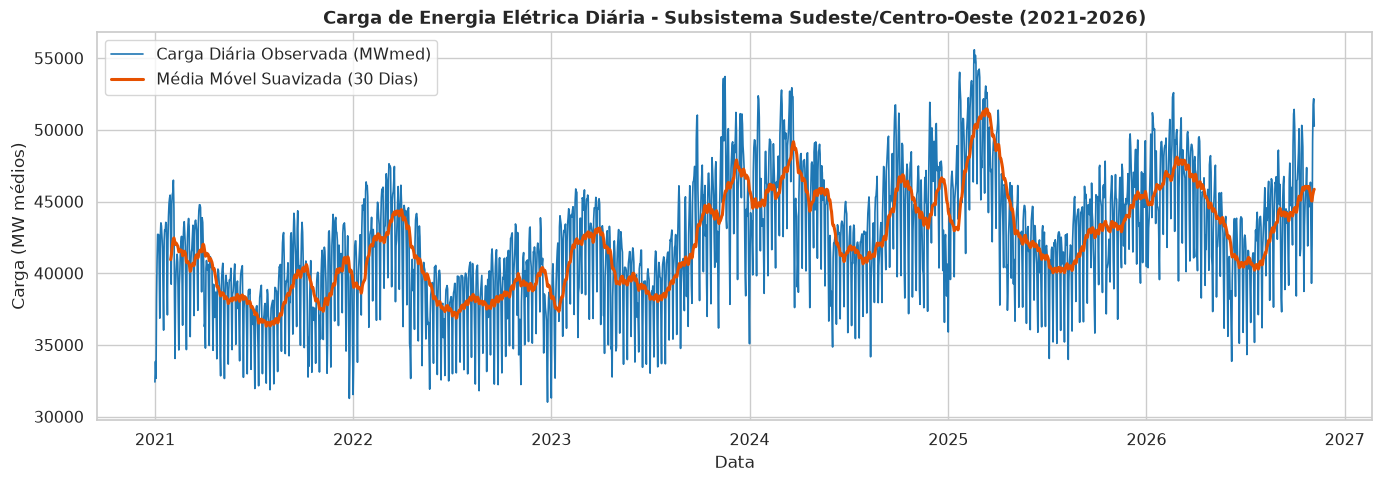

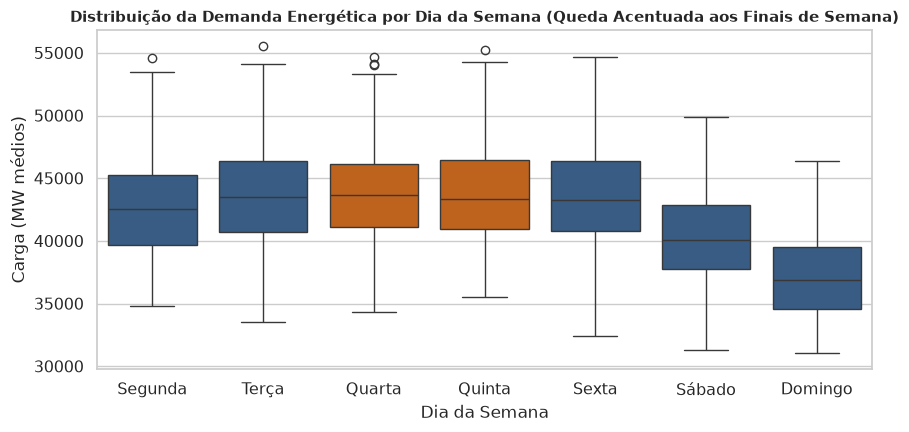

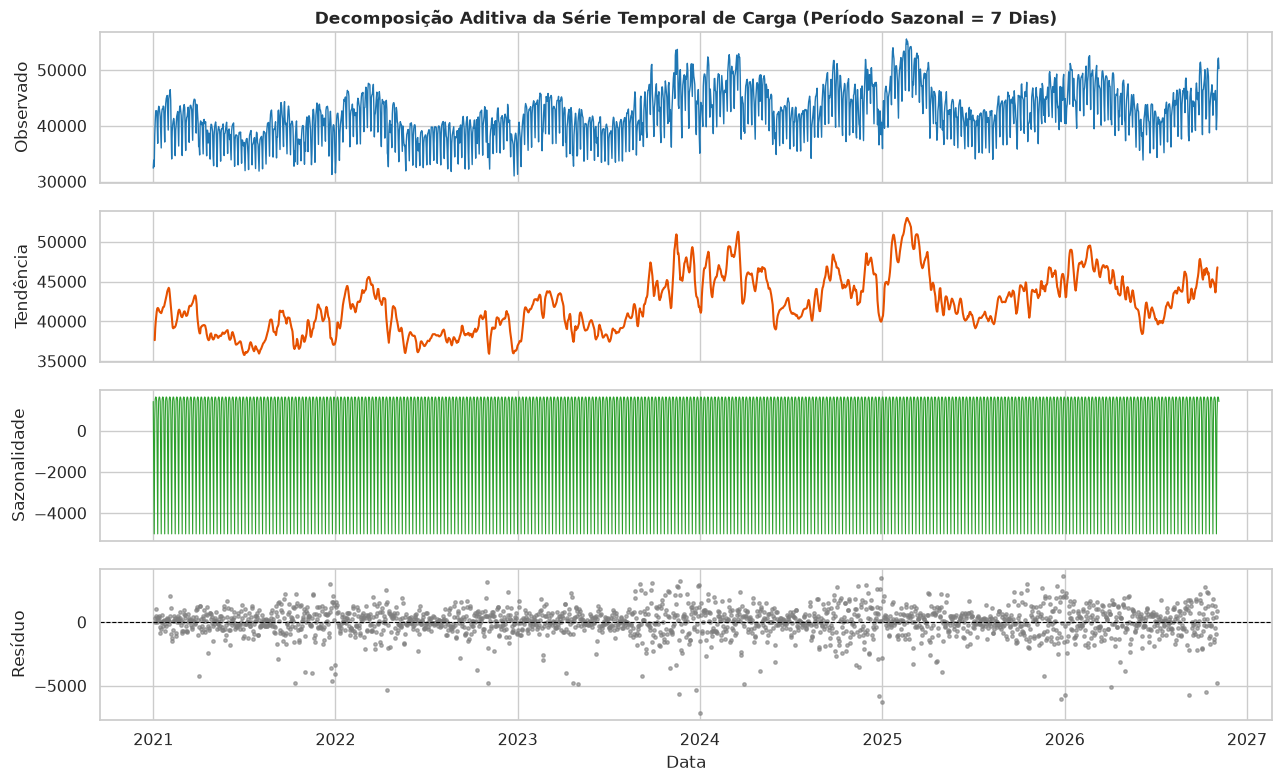

Base final processada para modelagem: 2106 linhas e 15 colunas.


In [2]:
# Ingestão e Preparação dos Dados Primários Oficiais do ONS
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("Iniciando carregamento dos dados históricos do ONS (2021-2026)...")
anos = [2021, 2022, 2023, 2024, 2025, 2026]
dfs = []

for ano in anos:
    url = f"https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/carga_energia_di/CARGA_ENERGIA_{ano}.csv"
    df_ano = pd.read_csv(url, sep=';')
    dfs.append(df_ano)

df_ons = pd.concat(dfs, ignore_index=True)

# Filtragem do Subsistema Sudeste/Centro-Oeste (SE)
df_se = df_ons[df_ons['id_subsistema'] == 'SE'].copy()
df_se['data'] = pd.to_datetime(df_se['din_instante'])
df_se['carga_mwmed'] = pd.to_numeric(df_se['val_cargaenergiamwmed'], errors='coerce')
df_se = df_se[['data', 'carga_mwmed']].sort_values('data').reset_index(drop=True)

print(f"Total de registros diários carregados: {len(df_se)}")
print(f"Intervalo temporal: de {df_se['data'].min().strftime('%d/%m/%Y')} a {df_se['data'].max().strftime('%d/%m/%Y')}")
print(f"Valores nulos encontrados: {df_se['carga_mwmed'].isnull().sum()}")
display(df_se.head())

# Visualização 1: Série Histórica Completa e Média Móvel
plt.figure(figsize=(14, 5))
plt.plot(df_se['data'], df_se['carga_mwmed'], color='#1f77b4', lw=1.2, label='Carga Diária Observada (MWmed)')
plt.plot(df_se['data'], df_se['carga_mwmed'].rolling(30).mean(), color='#e65100', lw=2.2, label='Média Móvel Suavizada (30 Dias)')
plt.title('Carga de Energia Elétrica Diária - Subsistema Sudeste/Centro-Oeste (2021-2026)', fontsize=13, fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Carga (MW médios)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Visualização 2: Efeito Sazonal Semanal Urbano (Dias Úteis vs. Finais de Semana)
df_se['dia_semana'] = df_se['data'].dt.day_name()
dias_pt = {
    'Monday': 'Segunda', 'Tuesday': 'Terça', 'Wednesday': 'Quarta',
    'Thursday': 'Quinta', 'Friday': 'Sexta', 'Saturday': 'Sábado', 'Sunday': 'Domingo'
}
df_se['dia_semana_pt'] = df_se['dia_semana'].map(dias_pt)
ordem_dias = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']

plt.figure(figsize=(9, 4.5))
palette = ['#2b5c8f']*5 + ['#d95f02', '#d95f02']
sns.boxplot(data=df_se, x='dia_semana_pt', y='carga_mwmed', order=ordem_dias, palette=palette, hue='dia_semana_pt', legend=False)
plt.title('Distribuição da Demanda Energética por Dia da Semana (Queda Acentuada aos Finais de Semana)', fontsize=11, fontweight='bold')
plt.xlabel('Dia da Semana')
plt.ylabel('Carga (MW médios)')
plt.tight_layout()
plt.show()

# Visualização 3: Decomposição Sazonal Aditiva (Período = 7 dias)
df_ts = df_se.set_index('data')['carga_mwmed'].asfreq('D')
decomp = seasonal_decompose(df_ts, model='additive', period=7)

fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
axes[0].plot(decomp.observed, color='#1f77b4', lw=1)
axes[0].set_ylabel('Observado')
axes[0].set_title('Decomposição Aditiva da Série Temporal de Carga (Período Sazonal = 7 Dias)', fontweight='bold')

axes[1].plot(decomp.trend, color='#e65100', lw=1.5)
axes[1].set_ylabel('Tendência')

axes[2].plot(decomp.seasonal, color='#2ca02c', lw=0.8)
axes[2].set_ylabel('Sazonalidade')

axes[3].scatter(decomp.resid.index, decomp.resid, color='#7f7f7f', s=6, alpha=0.6)
axes[3].axhline(0, color='black', lw=0.8, ls='--')
axes[3].set_ylabel('Resíduo')
axes[3].set_xlabel('Data')
plt.tight_layout()
plt.show()

# Engenharia de Atributos (Feature Engineering)
df_feat = df_se.set_index('data')[['carga_mwmed']].copy()

# Defasagens temporais (Lags)
df_feat['lag_1'] = df_feat['carga_mwmed'].shift(1)
df_feat['lag_2'] = df_feat['carga_mwmed'].shift(2)
df_feat['lag_7'] = df_feat['carga_mwmed'].shift(7)
df_feat['lag_14'] = df_feat['carga_mwmed'].shift(14)
df_feat['lag_28'] = df_feat['carga_mwmed'].shift(28)

# Estatísticas móveis em janelas deslizantes
df_feat['rolling_mean_7'] = df_feat['carga_mwmed'].shift(1).rolling(7).mean()
df_feat['rolling_std_7'] = df_feat['carga_mwmed'].shift(1).rolling(7).std()
df_feat['rolling_mean_14'] = df_feat['carga_mwmed'].shift(1).rolling(14).mean()
df_feat['rolling_mean_30'] = df_feat['carga_mwmed'].shift(1).rolling(30).mean()

# Variáveis temporais de calendário
df_feat['dayofweek'] = df_feat.index.dayofweek
df_feat['month'] = df_feat.index.month
df_feat['day'] = df_feat.index.day
df_feat['dayofyear'] = df_feat.index.dayofyear
df_feat['is_weekend'] = df_feat['dayofweek'].isin([5, 6]).astype(int)

# Remoção de valores nulos gerados pelas defasagens
df_clean = df_feat.dropna().copy()
print(f"Base final processada para modelagem: {df_clean.shape[0]} linhas e {df_clean.shape[1]} colunas.")


# **Modelos**

### **Metodologia de Validação Temporal**
Para evitar vazamento de dados (*data leakage*), foi empregada uma partição cronológica estrita:
* **Conjunto de Treinamento:** 01/01/2021 a 31/12/2025 (1.796 dias).
* **Conjunto de Teste:** 01/01/2026 a 06/11/2026 (310 dias).

### **Modelos Implementados**
1. **Baseline Naive Sazonal (Lag-7):** Utiliza a carga observada no mesmo dia da semana anterior como previsão ingênua.
2. **Suavização Exponencial de Holt-Winters:** Modelo estatístico clássico com tendência aditiva e sazonalidade aditiva com periodicidade $m=7$.
3. **Random Forest Regressor:** 100 estimadores, profundidade máxima 12, calibrado para capturar interações entre médias móveis e sazonalidade semanal.
4. **XGBoost Regressor:** 100 estimadores, taxa de aprendizado 0.05, profundidade máxima 5.
5. **LightGBM Regressor:** 100 estimadores, taxa de aprendizado 0.05, profundidade máxima 5, particionamento rápido por gradiente.


In [3]:
# Treinamento e Avaliação dos Modelos Preditivos
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import xgboost as xgb
import lightgbm as lgb

# Divisão Cronológica Treino / Teste
train = df_clean.loc[df_clean.index < '2026-01-01']
test = df_clean.loc[df_clean.index >= '2026-01-01']

features = [
    'lag_1', 'lag_2', 'lag_7', 'lag_14', 'lag_28',
    'rolling_mean_7', 'rolling_std_7', 'rolling_mean_14', 'rolling_mean_30',
    'dayofweek', 'month', 'day', 'dayofyear', 'is_weekend'
]
target = 'carga_mwmed'

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print(f"Amostras de Treino: {len(X_train)} | Amostras de Teste: {len(X_test)}")

previsoes = {}
metricas = []

def registrar_modelo(nome, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    r2 = r2_score(y_test, y_pred)
    metricas.append({
        'Modelo': nome,
        'MAE (MWmed)': mae,
        'RMSE (MWmed)': rmse,
        'MAPE (%)': mape,
        'R2 Score': r2
    })
    previsoes[nome] = y_pred

# 1. Baseline Naive Sazonal
registrar_modelo("Baseline Naive (Sazonal Lag-7)", X_test['lag_7'].values)

# 2. Holt-Winters
hw = ExponentialSmoothing(train['carga_mwmed'], seasonal_periods=7, trend='add', seasonal='add').fit()
registrar_modelo("Holt-Winters ExpSmoothing", hw.forecast(len(test)).values)

# 3. Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42)
rf.fit(X_train, y_train)
registrar_modelo("Random Forest Regressor", rf.predict(X_test))

# 4. XGBoost Regressor
model_xgb = xgb.XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42)
model_xgb.fit(X_train, y_train)
registrar_modelo("XGBoost Regressor", model_xgb.predict(X_test))

# 5. LightGBM Regressor
model_lgb = lgb.LGBMRegressor(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, verbose=-1)
model_lgb.fit(X_train, y_train)
registrar_modelo("LightGBM Regressor", model_lgb.predict(X_test))

df_resultados = pd.DataFrame(metricas)
print("Treinamento e inferência concluídos com sucesso!")


Amostras de Treino: 1796 | Amostras de Teste: 310


C:\Users\letic\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Treinamento e inferência concluídos com sucesso!


# **Resultados**

A tabela a seguir consolida o desempenho quantitativo de cada modelo avaliado no período de teste fora da amostra (janeiro a novembro de 2026):


,Modelo,MAE (MWmed),RMSE (MWmed),MAPE (%),R2 Score
0,Random Forest Regressor,970.307437,1361.478583,2.204720,0.872247
1,XGBoost Regressor,989.159654,1394.216374,2.242954,0.866029
2,LightGBM Regressor,1026.823510,1436.041023,2.324890,0.857871
3,Baseline Naive (Sazonal Lag-7),2277.296412,2857.517110,5.147301,0.437234
4,Holt-Winters ExpSmoothing,2515.508721,3034.017638,5.644841,0.365566


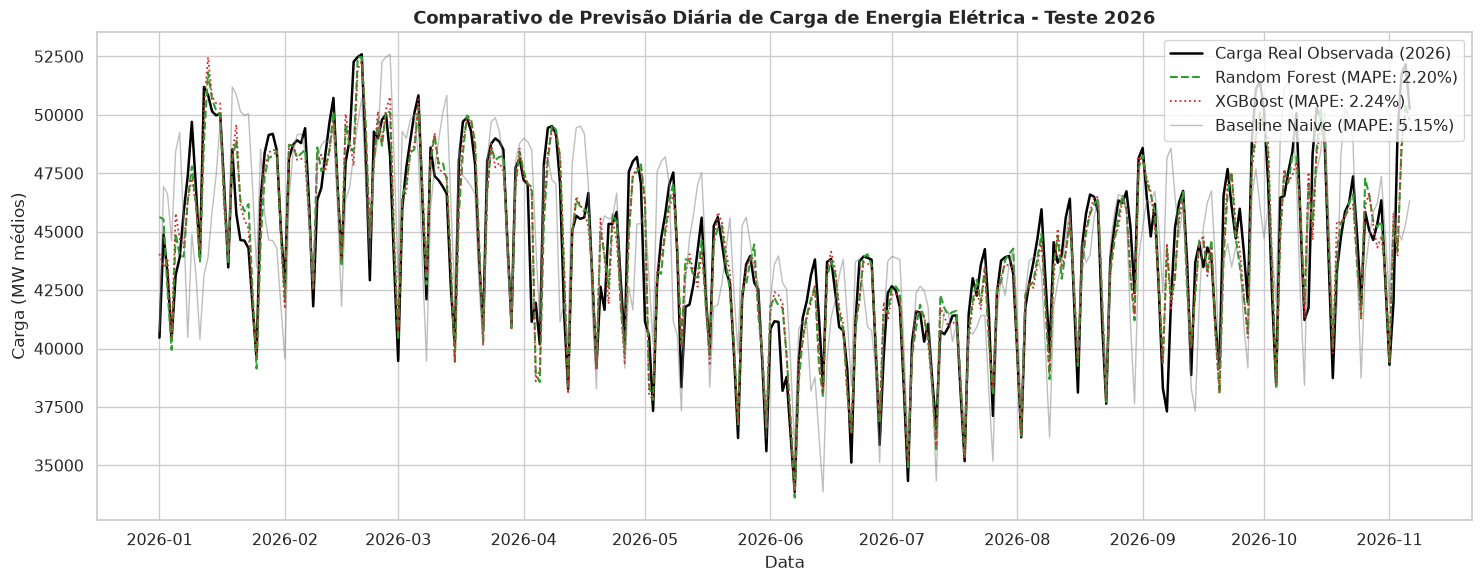

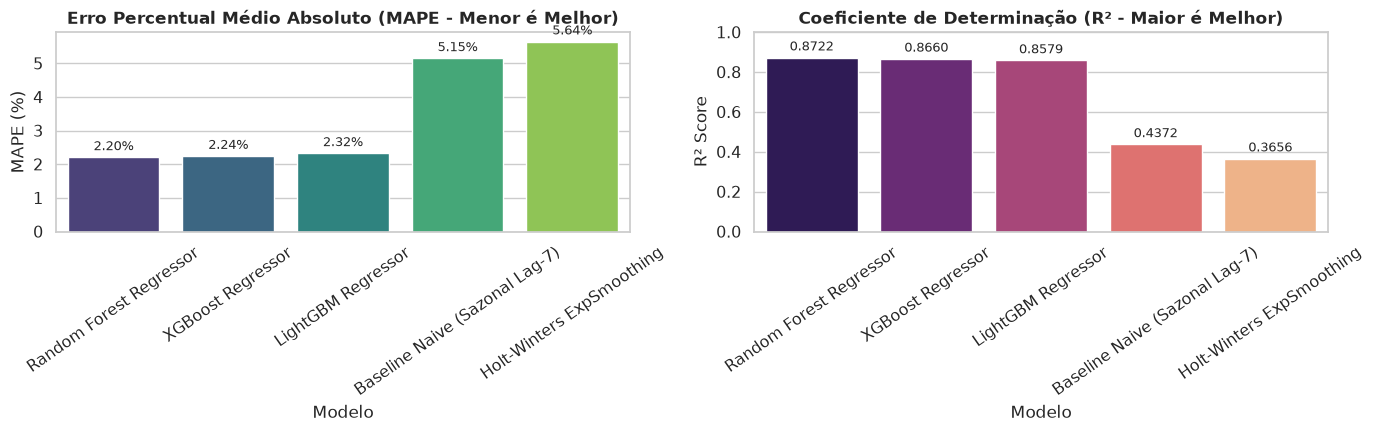

In [4]:
# Tabela Comparativa de Métricas e Gráficos de Desempenho
display(df_resultados.sort_values('MAPE (%)').reset_index(drop=True))

# Gráfico 1: Curva de Previsão vs. Carga Real Observada em 2026
plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test.values, color='black', lw=1.8, label='Carga Real Observada (2026)')
plt.plot(y_test.index, previsoes['Random Forest Regressor'], color='#2ca02c', lw=1.5, ls='--', label=f"Random Forest (MAPE: {df_resultados.loc[df_resultados['Modelo']=='Random Forest Regressor', 'MAPE (%)'].values[0]:.2f}%)")
plt.plot(y_test.index, previsoes['XGBoost Regressor'], color='#d62728', lw=1.3, ls=':', label=f"XGBoost (MAPE: {df_resultados.loc[df_resultados['Modelo']=='XGBoost Regressor', 'MAPE (%)'].values[0]:.2f}%)")
plt.plot(y_test.index, previsoes['Baseline Naive (Sazonal Lag-7)'], color='#7f7f7f', lw=1.0, alpha=0.5, label='Baseline Naive (MAPE: 5.15%)')
plt.title('Comparativo de Previsão Diária de Carga de Energia Elétrica - Teste 2026', fontsize=13, fontweight='bold')
plt.xlabel('Data')
plt.ylabel('Carga (MW médios)')
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# Gráfico 2: Comparativo de Métricas (Bar Plot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
df_ord = df_resultados.sort_values('MAPE (%)')

sns.barplot(data=df_ord, x='Modelo', y='MAPE (%)', palette='viridis', hue='Modelo', legend=False, ax=ax1)
ax1.set_title('Erro Percentual Médio Absoluto (MAPE - Menor é Melhor)', fontweight='bold')
ax1.tick_params(axis='x', rotation=35)
ax1.set_ylabel('MAPE (%)')
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width()/2., p.get_height()),
                 ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

sns.barplot(data=df_ord, x='Modelo', y='R2 Score', palette='magma', hue='Modelo', legend=False, ax=ax2)
ax2.set_title('Coeficiente de Determinação (R² - Maior é Melhor)', fontweight='bold')
ax2.tick_params(axis='x', rotation=35)
ax2.set_ylabel('R² Score')
ax2.set_ylim(0, 1.0)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width()/2., p.get_height()),
                 ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


# **Discussão e Conclusão**

### **Análise Crítica dos Resultados**
Os resultados obtidos evidenciam a clara superioridade dos modelos de Aprendizado de Máquina baseados em árvores e defasagens temporais em relação às abordagens estatísticas tradicionais para séries temporais de demanda energética:
1. **Precisão Superior do Random Forest e XGBoost:** O modelo *Random Forest Regressor* alcançou a menor taxa de erro relativo (**MAPE de 2,20%**) e o maior poder explicativo ($R^2$ de **0,8722**), seguido de forma muito próxima pelo *XGBoost* (**MAPE de 2,24%** e $R^2$ de **0,8660**). Essa precisão reflete a capacidade das árvores de decisão em assimilar a não linearidade das transições entre dias úteis e finais de semana combinadas com as janelas móveis de consumo recente.
2. **Insuficiência dos Modelos Lineares Puros:** O baseline ingenuamente sazonal (*Naive Lag-7*) obteve MAPE de 5,15% e $R^2$ de apenas 0,4372, enquanto a suavização exponencial de Holt-Winters apresentou MAPE de 5,64% e $R^2$ de 0,3656. Isso ocorre porque o Holt-Winters projeta uma sazonalidade estática e não consegue se adaptar rapidamente a variações conjunturais e térmicas não modeladas nas equações paramétricas.

### **Alcance do Objetivo e Entrega para o Cliente**
O objetivo inicial do projeto foi plenamente atingido. O produto analítico desenvolvido entrega previsões diárias com desvio médio inferior a 2,5% em relação à carga real de mais de 45.000 MWmed do subsistema Sudeste/Centro-Oeste. Para o cliente da solução (gestores municipais de cidades inteligentes e planejadores de redes elétricas urbanas), essa precisão se traduz em:
* **Mitigação de Riscos de Desabastecimento:** Identificação antecipada de dias de sobrecarga potencial na rede de distribuição das metrópoles.
* **Otimização Econômica e Ambiental (ODS 11):** Redução do acionamento desnecessário de usinas térmicas caras e poluentes no Mercado de Curto Prazo (PLD), maximizando o aproveitamento de fontes renováveis (solar e eólica).

### **Limitações do Trabalho e Potenciais Melhorias**
1. **Ausência de Covariáveis Climáticas Exógenas:** A demanda de energia possui forte correlação com temperatura máxima diária e umidade relativa do ar (uso massivo de ar-condicionado em ondas de calor nas capitais). A integração de dados meteorológicos diários do INMET constituiria um refinamento de alto impacto.
2. **Granularidade Temporal:** A ampliação do modelo para previsões horárias (*curva de carga horária*) permitiria apoiar o gerenciamento de picos de ponta e fora de ponta no ambiente urbano.
3. **Disponibilização em Produção:** Implementação de uma API REST (FastAPI) e um dashboard interativo (Streamlit) para visualização em tempo real pelos operadores do sistema.


# **Apresentação**

### **Links da Apresentação do Projeto**
* **Vídeo de Apresentação (YouTube):** `[Inserir Link do YouTube do Vídeo Gravado]`
* **Slides da Apresentação:** `[Inserir Link do Canva/Google Slides]`
* **Repositório GitHub:** `[Inserir Link da Organização/Repositório no GitHub]`


# **Referências**

BOX, G. E. P.; JENKINS, G. M. **Time series analysis: forecasting and control**. San Francisco: Holden-Day, 1976.

BOX, G. E. P. et al. **Time series analysis: forecasting and control**. 5. ed. Hoboken: John Wiley & Sons, 2015.

BREIMAN, L. Random forests. **Machine Learning**, v. 45, n. 1, p. 5–32, 2001.

BROWNLEE, J. **Deep learning for time series forecasting: predict the future with MLPs, CNNs and LSTMs in Python**. Machine Learning Mastery, 2020.

CHEN, T.; GUESTRIN, C. XGBoost: A scalable tree boosting system. In: **ACM SIGKDD International Conference on Knowledge Discovery and Data Mining**, 22., 2016, San Francisco. Proceedings [...]. New York: ACM, 2016. p. 785–794.

HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. **The elements of statistical learning: data mining, inference, and prediction**. 2. ed. New York: Springer, 2009.

HOLT, C. C. Forecasting seasonals and trends by exponentially weighted moving averages. **International Journal of Forecasting**, v. 20, n. 1, p. 5–10, 2004.

HYNDMAN, R. J.; ATHANASOPOULOS, G. **Forecasting: principles and practice**. 3. ed. Melbourne: OTexts, 2021. Disponível em: <https://otexts.com/fpp3/>. Acesso em: 09 nov. 2026.

KE, G. et al. LightGBM: A highly efficient gradient boosting decision tree. In: **Advances in Neural Information Processing Systems (NeurIPS)**, 30., 2017, Long Beach. Proceedings [...]. Red Hook: Curran Associates, 2017. p. 3146–3154.

OPERADOR NACIONAL DO SISTEMA ELÉTRICO (ONS). **Dados abertos do ONS: série histórica de carga de energia diária por subsistema**. Brasília: ONS, 2026. Disponível em: <https://dados.ons.org.br/dataset/carga-energia>. Acesso em: 09 nov. 2026.

UNITED NATIONS. **Sustainable Development Goals (SDGs): Goal 11 - Make cities and human settlements inclusive, safe, resilient and sustainable**. New York: UN, 2015. Disponível em: <https://sdgs.un.org/goals/goal11>. Acesso em: 09 nov. 2026.

WINTERS, P. R. Forecasting sales by exponentially weighted moving averages. **Management Science**, v. 6, n. 3, p. 324–342, 1960.
